# GEnKF

## Filtering distribution at $T=10$

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from rainfall import *
from enkf import *

In [3]:
data = load_data("./data/rainfall.pt")
theta = data["theta"]
x = data["x"]
stations = data["stations"]
y = data["y"]
z = data["z"]
meta = data["meta"]

In [4]:
torch.manual_seed(548)
particles, log_weights = genkf(stations, z, n=100, T=10)

In [5]:
theta[10]

tensor(2.4623)

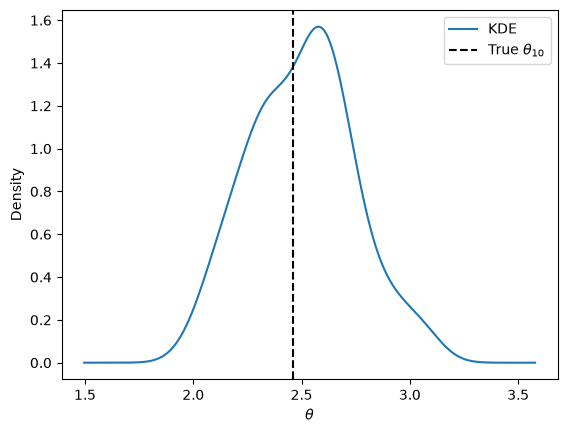

In [6]:
import numpy as np
from plots import *

t = 10
thetas = torch.stack([torch.as_tensor(p[0]) for p in particles]).numpy()
plot_theta(thetas, theta[t].item(), t,
    save="figures/genkf_filtering_theta.png")

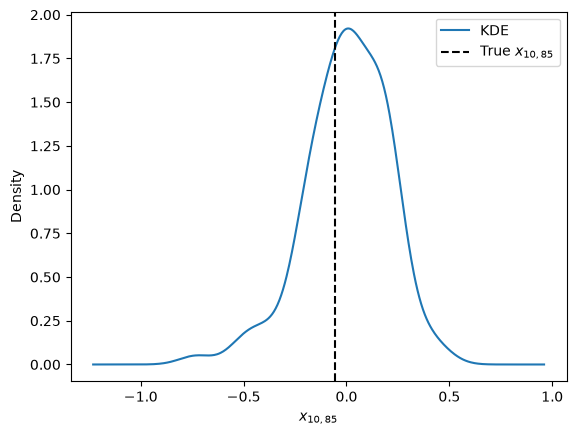

In [7]:
# Posterior samples of x are the ensemble members, which are equally weighted
X = torch.stack([p[1] for p in particles]).numpy() # (n, grid)

rng = np.random.default_rng(0)
k = rng.integers(X.shape[1])
plot_state_marginal(X, x[t].numpy(), t, k,
    save="figures/genkf_filtering_marginal.png")

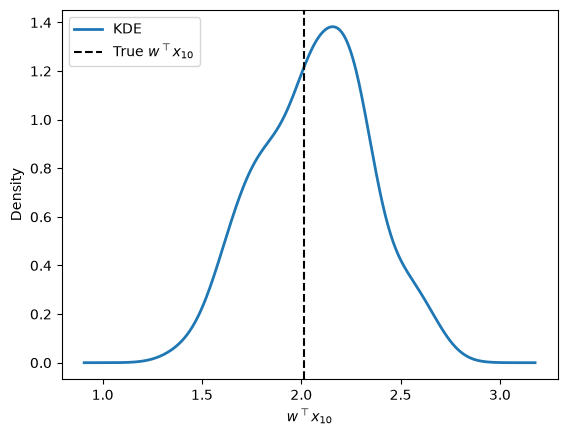

In [8]:
w = rng.standard_normal(X.shape[1])
w /= np.linalg.norm(w)
plot_projection(X, x[t].numpy(), t, w,
    save="figures/genkf_filtering_projection.png")

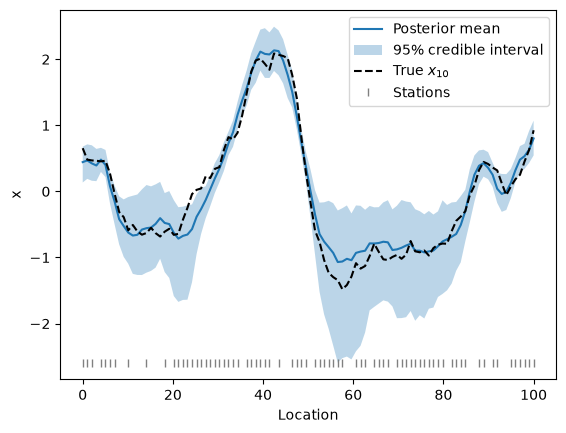

In [9]:
plot_state_band(X, x[t].numpy(), t, stations,
    save="figures/genkf_filtering_band.png")

In [ ]:
from metrics import record_metrics
record_metrics("results/genkf.csv", "filtering_T10", X, x[t].numpy())

## Single up-date at $T=10$

In [10]:
torch.manual_seed(548)
particles, log_weights = genkf(stations, z[9:10], n=100, T=10)

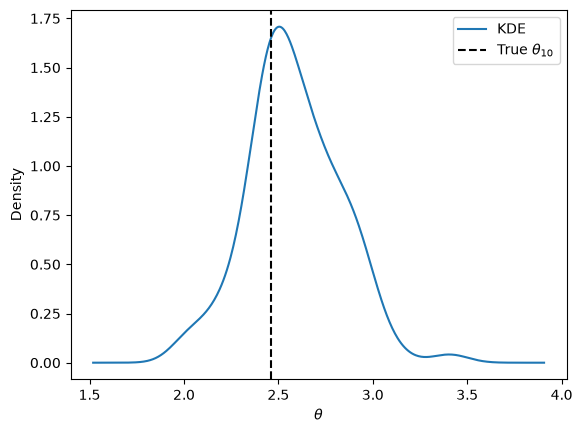

In [11]:
thetas = torch.stack([torch.as_tensor(p[0]) for p in particles]).numpy()
plot_theta(thetas, theta[t].item(), t,
    save="figures/genkf_single_update_theta.png")

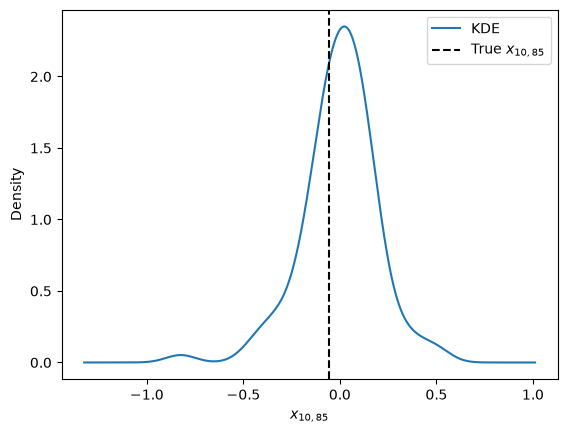

In [12]:
X = torch.stack([p[1] for p in particles]).numpy() # (n, grid)

rng = np.random.default_rng(0)
k = rng.integers(X.shape[1])
plot_state_marginal(X, x[t].numpy(), t, k,
    save="figures/genkf_single_update_marginal.png")

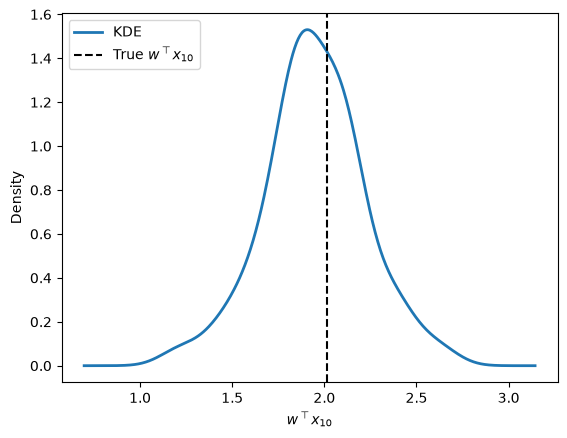

In [13]:
w = rng.standard_normal(X.shape[1])
w /= np.linalg.norm(w)
plot_projection(X, x[t].numpy(), t, w,
    save="figures/genkf_single_update_projection.png")

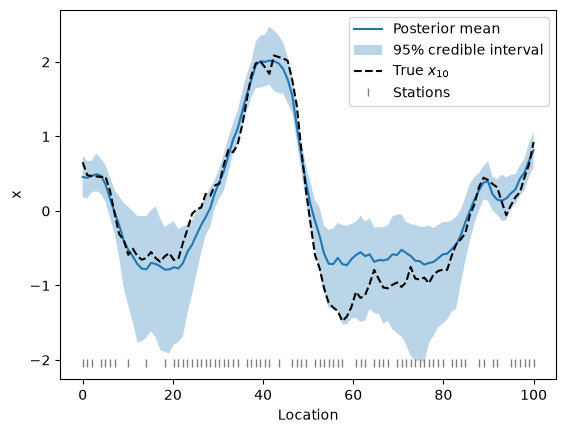

In [14]:
plot_state_band(X, x[t].numpy(), t, stations,
    save="figures/genkf_single_update_band.png")

In [ ]:
record_metrics("results/genkf.csv", "single_update_T10", X, x[t].numpy())